In [3]:
import os
import shutil
import random

# Original dataset
source_dir = r"C:\Users\usER\Downloads\archive\Data"

# New smaller dataset
target_dir = r"C:\Users\usER\Downloads\balanced_data"

# Samples per class
samples_per_class = 2000

# Create target folder
if not os.path.exists(target_dir):
    os.makedirs(target_dir)

for class_name in os.listdir(source_dir):
    src_class = os.path.join(source_dir, class_name)
    dst_class = os.path.join(target_dir, class_name)

    os.makedirs(dst_class, exist_ok=True)

    images = os.listdir(src_class)
    selected = random.sample(images, min(samples_per_class, len(images)))

    for img in selected:
        shutil.copy(
            os.path.join(src_class, img),
            os.path.join(dst_class, img)
        )

print("Balanced dataset created!")

Balanced dataset created!


2800 600 600
Found 2800 validated image filenames.
Found 600 validated image filenames.
Found 600 validated image filenames.
Epoch 1/10


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


88/88 ━━━━━━━━━━━━━━━━━━━━ 1240s 14s/step - accuracy: 0.5013 - loss: 0.7491 - val_accuracy: 0.6317 - val_loss: 0.6609
Epoch 2/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 1229s 14s/step - accuracy: 0.6403 - loss: 0.6319 - val_accuracy: 0.7333 - val_loss: 0.5082
Epoch 3/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 4292s 49s/step - accuracy: 0.7700 - loss: 0.4877 - val_accuracy: 0.7483 - val_loss: 0.4922
Epoch 4/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 1022s 12s/step - accuracy: 0.7867 - loss: 0.4487 - val_accuracy: 0.8200 - val_loss: 0.4051
Epoch 5/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 1053s 12s/step - accuracy: 0.8089 - loss: 0.4232 - val_accuracy: 0.7967 - val_loss: 0.4367
Epoch 6/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 1077s 12s/step - accuracy: 0.8392 - loss: 0.3844 - val_accuracy: 0.8517 - val_loss: 0.3485
Epoch 7/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 1077s 12s/step - accuracy: 0.8197 - loss: 0.4064 - val_accuracy: 0.8467 - val_loss: 0.3448
Epoch 8/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 1072s 12s/step - accuracy: 0.8457 - loss: 0.3412 - val_accuracy: 0.856

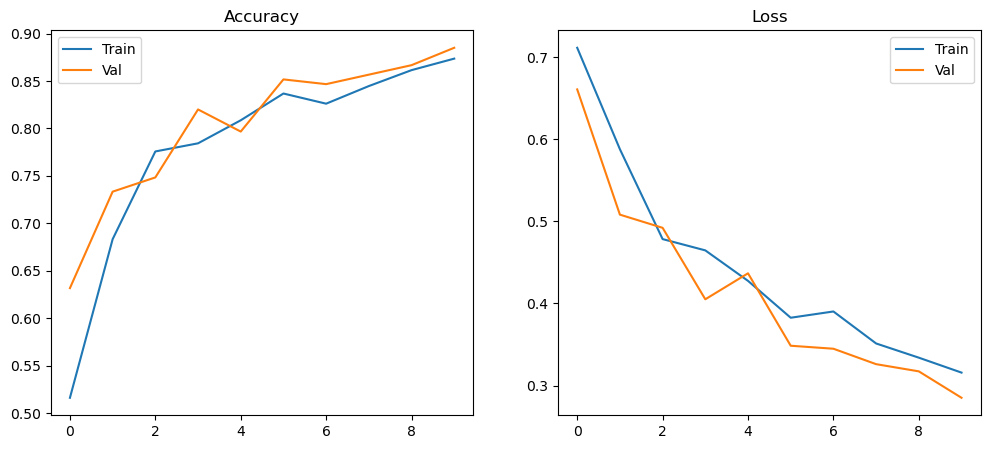

19/19 ━━━━━━━━━━━━━━━━━━━━ 164s 9s/step - accuracy: 0.8413 - loss: 0.3549
Test Accuracy: 0.8500000238418579
19/19 ━━━━━━━━━━━━━━━━━━━━ 167s 9s/step


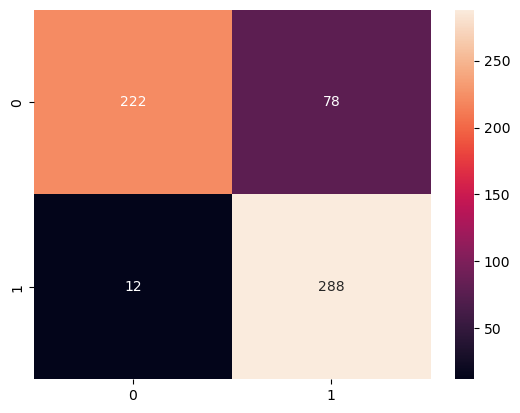

              precision    recall  f1-score   support

           0       0.95      0.74      0.83       300
           1       0.79      0.96      0.86       300

    accuracy                           0.85       600
   macro avg       0.87      0.85      0.85       600
weighted avg       0.87      0.85      0.85       600



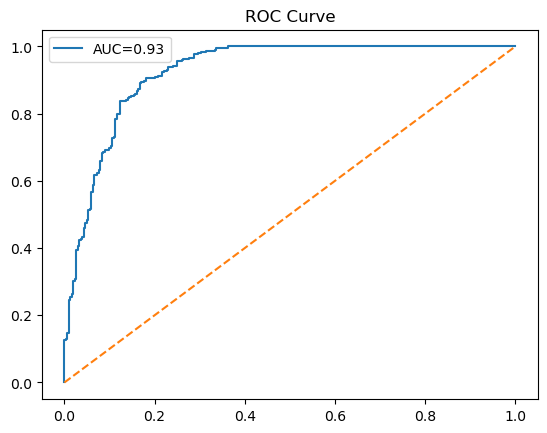

In [12]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

# =========================
# 1. PATH (YOUR DATA)
# =========================
r"C:\Users\usER\Downloads\balanced_data"

categories = ['Non Demented', 'Very mild Dementia']

image_paths = []
labels = []

# =========================
# 2. LOAD DATA
# =========================
for category in categories:
    folder = os.path.join(base_path, category)
    for file in os.listdir(folder):
        image_paths.append(os.path.join(folder, file))
        labels.append(category)

df = pd.DataFrame({'image_path': image_paths, 'label': labels})

# Convert to binary
df['label'] = df['label'].map({
    'Non Demented': 0,
    'Very mild Dementia': 1
})

# =========================
# 3. SPLIT
# =========================
train_df, temp_df = train_test_split(df, test_size=0.3, stratify=df['label'], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df['label'], random_state=42)

print(len(train_df), len(val_df), len(test_df))

# =========================
# 4. AUGMENTATION
# =========================
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.15,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1./255)

# =========================
# 5. GENERATORS
# =========================
train_gen = train_datagen.flow_from_dataframe(
    train_df,
    x_col='image_path',
    y_col='label',
    target_size=(224,224),
    batch_size=32,
    class_mode='raw'
)

val_gen = val_datagen.flow_from_dataframe(
    val_df,
    x_col='image_path',
    y_col='label',
    target_size=(224,224),
    batch_size=32,
    class_mode='raw'
)

test_gen = val_datagen.flow_from_dataframe(
    test_df,
    x_col='image_path',
    y_col='label',
    target_size=(224,224),
    batch_size=32,
    class_mode='raw',
    shuffle=False
)

# =========================
# 6. MODEL (VGG16)
# =========================
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224,224,3))

# Freeze most layers
for layer in base_model.layers[:-4]:
    layer.trainable = False

model = Sequential([
    base_model,
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

# =========================
# 7. COMPILE
# =========================
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# =========================
# 8. TRAIN (ONLY ONCE)
# =========================
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10
)

# =========================
# 9. PLOT
# =========================
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.legend()
plt.title("Accuracy")

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.legend()
plt.title("Loss")

plt.show()

# =========================
# 10. TEST
# =========================
test_loss, test_acc = model.evaluate(test_gen)
print("Test Accuracy:", test_acc)

# =========================
# 11. RESULTS
# =========================
y_true = test_df['label'].values
y_probs = model.predict(test_gen)
y_pred = (y_probs > 0.5).astype(int)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.show()

print(classification_report(y_true, y_pred))

# =========================
# 12. ROC
# =========================
fpr, tpr, _ = roc_curve(y_true, y_probs)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC={roc_auc:.2f}")
plt.plot([0,1],[0,1],'--')
plt.legend()
plt.title("ROC Curve")
plt.show()

In [14]:
# =========================
# SAVE MODEL
# =========================
model.save("vgg16_dementia_model.keras")

2800 600 600
Found 2800 validated image filenames.
Found 600 validated image filenames.
Found 600 validated image filenames.
Epoch 1/20


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


88/88 ━━━━━━━━━━━━━━━━━━━━ 1096s 12s/step - accuracy: 0.5289 - loss: 0.7246 - val_accuracy: 0.5800 - val_loss: 0.6560
Epoch 2/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 1125s 13s/step - accuracy: 0.7137 - loss: 0.5717 - val_accuracy: 0.7350 - val_loss: 0.5181
Epoch 3/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 1124s 13s/step - accuracy: 0.7666 - loss: 0.5079 - val_accuracy: 0.8033 - val_loss: 0.4459
Epoch 4/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 1129s 13s/step - accuracy: 0.8017 - loss: 0.4378 - val_accuracy: 0.8400 - val_loss: 0.3834
Epoch 5/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 1124s 13s/step - accuracy: 0.8219 - loss: 0.3953 - val_accuracy: 0.8667 - val_loss: 0.3461
Epoch 6/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 1119s 13s/step - accuracy: 0.8453 - loss: 0.3726 - val_accuracy: 0.8483 - val_loss: 0.3356
Epoch 7/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 1128s 13s/step - accuracy: 0.8366 - loss: 0.3819 - val_accuracy: 0.8417 - val_loss: 0.3635
Epoch 8/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 1127s 13s/step - accuracy: 0.8511 - loss: 0.3313 - val_accuracy: 0.865

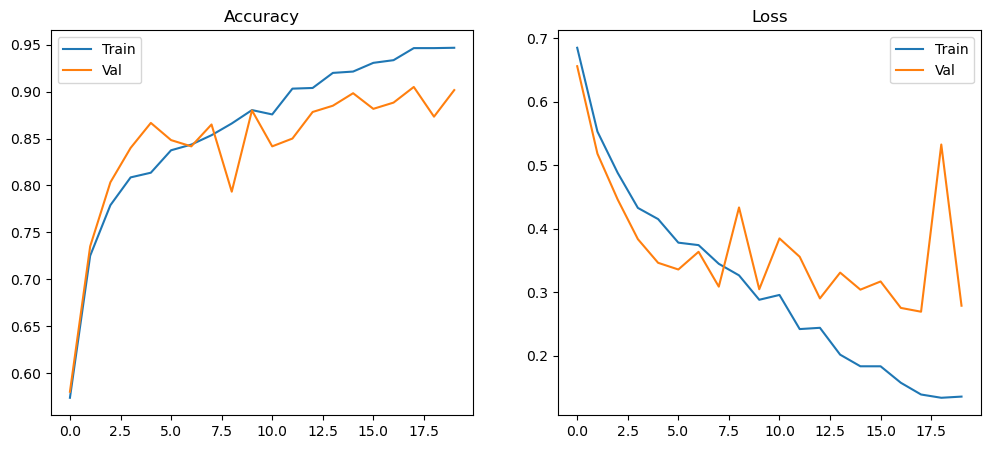

19/19 ━━━━━━━━━━━━━━━━━━━━ 167s 9s/step - accuracy: 0.8860 - loss: 0.3432
Test Accuracy: 0.8766666650772095
19/19 ━━━━━━━━━━━━━━━━━━━━ 169s 9s/step


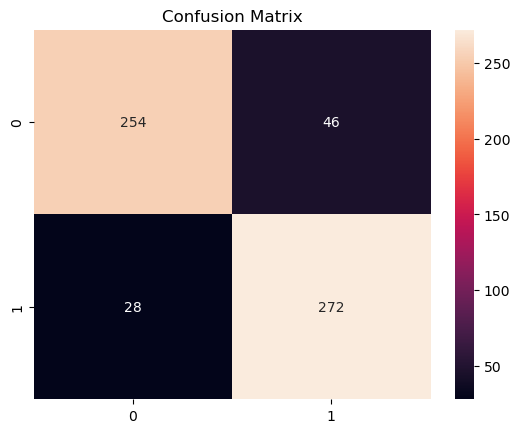

              precision    recall  f1-score   support

           0       0.90      0.85      0.87       300
           1       0.86      0.91      0.88       300

    accuracy                           0.88       600
   macro avg       0.88      0.88      0.88       600
weighted avg       0.88      0.88      0.88       600



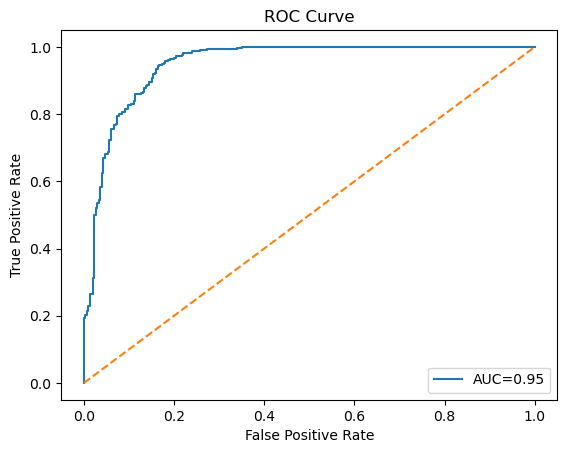

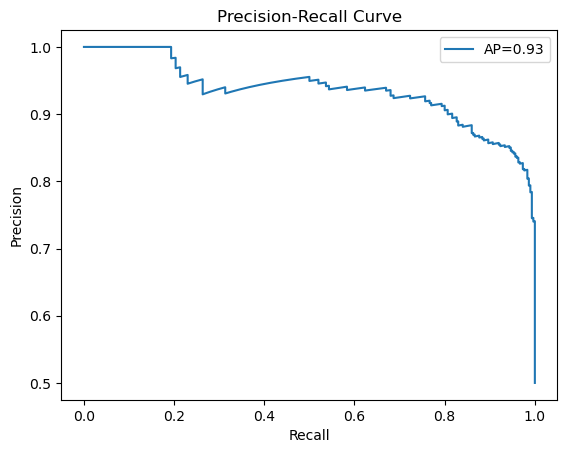

Sensitivity: 0.9067
Specificity: 0.8467
19/19 ━━━━━━━━━━━━━━━━━━━━ 167s 9s/step
Total Inference Time: 166.9711 sec
Time per Image: 0.278285 sec
Model Size: 184.11 MB


In [36]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import time

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

# =========================
# 1. PATH
# =========================
base_path = r"C:\Users\usER\Downloads\balanced_data"

categories = ['Non Demented', 'Very mild Dementia']

image_paths = []
labels = []

# =========================
# 2. LOAD DATA
# =========================
for category in categories:
    folder = os.path.join(base_path, category)
    for file in os.listdir(folder):
        image_paths.append(os.path.join(folder, file))
        labels.append(category)

df = pd.DataFrame({'image_path': image_paths, 'label': labels})

df['label'] = df['label'].map({
    'Non Demented': 0,
    'Very mild Dementia': 1
})

# =========================
# 3. SPLIT
# =========================
train_df, temp_df = train_test_split(
    df, test_size=0.3, stratify=df['label'], random_state=42
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['label'], random_state=42
)

print(len(train_df), len(val_df), len(test_df))

# =========================
# 4. AUGMENTATION
# =========================
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.15,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1./255)

# =========================
# 5. GENERATORS
# =========================
train_gen = train_datagen.flow_from_dataframe(
    train_df,
    x_col='image_path',
    y_col='label',
    target_size=(224,224),
    batch_size=32,
    class_mode='raw'
)

val_gen = val_datagen.flow_from_dataframe(
    val_df,
    x_col='image_path',
    y_col='label',
    target_size=(224,224),
    batch_size=32,
    class_mode='raw'
)

test_gen = val_datagen.flow_from_dataframe(
    test_df,
    x_col='image_path',
    y_col='label',
    target_size=(224,224),
    batch_size=32,
    class_mode='raw',
    shuffle=False
)

# =========================
# 6. MODEL
# =========================
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224,224,3))

for layer in base_model.layers[:-4]:
    layer.trainable = False

model = Sequential([
    base_model,
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

# =========================
# 7. COMPILE
# =========================
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# =========================
# 8. TRAIN (20 EPOCHS)
# =========================
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20
)

# =========================
# 9. SAVE MODEL (.h5)
# =========================
model.save("vgg16_model.h5")

# =========================
# 10. PLOTS
# =========================
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.legend()
plt.title("Accuracy")

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.legend()
plt.title("Loss")

plt.show()

# =========================
# 11. TEST
# =========================
test_loss, test_acc = model.evaluate(test_gen)
print("Test Accuracy:", test_acc)

# =========================
# 12. PREDICTIONS
# =========================
y_true = test_df['label'].values
y_probs = model.predict(test_gen)
y_pred = (y_probs > 0.5).astype(int)

# =========================
# 13. CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()

print(classification_report(y_true, y_pred))

# =========================
# 14. ROC CURVE
# =========================
fpr, tpr, _ = roc_curve(y_true, y_probs)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC={roc_auc:.2f}")
plt.plot([0,1],[0,1],'--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.title("ROC Curve")
plt.show()

# =========================
# 15. PR CURVE
# =========================
precision, recall, _ = precision_recall_curve(y_true, y_probs)
ap_score = average_precision_score(y_true, y_probs)

plt.plot(recall, precision, label=f"AP={ap_score:.2f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.title("Precision-Recall Curve")
plt.show()

# =========================
# 16. SENSITIVITY & SPECIFICITY
# =========================
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

print("Sensitivity:", round(sensitivity, 4))
print("Specificity:", round(specificity, 4))

# =========================
# 17. INFERENCE TIME
# =========================
start = time.time()
_ = model.predict(test_gen)
end = time.time()

total_time = end - start
avg_time = total_time / len(test_df)

print("Total Inference Time:", round(total_time, 4), "sec")
print("Time per Image:", round(avg_time, 6), "sec")

# =========================
# 18. MODEL SIZE
# =========================
size_mb = os.path.getsize("vgg16_model.h5") / (1024 * 1024)
print("Model Size:", round(size_mb, 2), "MB")

2800 600 600
Found 2800 validated image filenames.
Found 600 validated image filenames.
Found 600 validated image filenames.


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


88/88 ━━━━━━━━━━━━━━━━━━━━ 323s 4s/step - accuracy: 0.5429 - loss: 1.2234 - val_accuracy: 0.6183 - val_loss: 0.6682
Epoch 2/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 298s 3s/step - accuracy: 0.6100 - loss: 0.6898 - val_accuracy: 0.5000 - val_loss: 0.7956
Epoch 3/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 278s 3s/step - accuracy: 0.6591 - loss: 0.6189 - val_accuracy: 0.5000 - val_loss: 1.2928
Epoch 4/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 279s 3s/step - accuracy: 0.6749 - loss: 0.5863 - val_accuracy: 0.5000 - val_loss: 0.9912
Epoch 5/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 279s 3s/step - accuracy: 0.6968 - loss: 0.5765 - val_accuracy: 0.5000 - val_loss: 0.8859
Epoch 6/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 284s 3s/step - accuracy: 0.7098 - loss: 0.5661 - val_accuracy: 0.5817 - val_loss: 0.7258
Epoch 7/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 291s 3s/step - accuracy: 0.7323 - loss: 0.5436 - val_accuracy: 0.7517 - val_loss: 0.5191
Epoch 8/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 319s 4s/step - accuracy: 0.7464 - loss: 0.5045 - val_accuracy: 0.7733 - val_loss: 0.

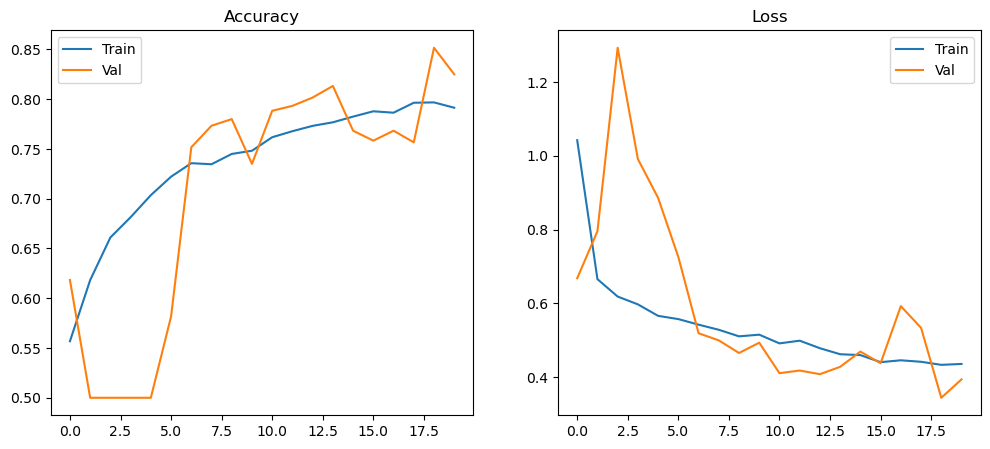

19/19 ━━━━━━━━━━━━━━━━━━━━ 14s 760ms/step - accuracy: 0.8146 - loss: 0.4104
Test Accuracy: 0.8083333373069763
19/19 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step 


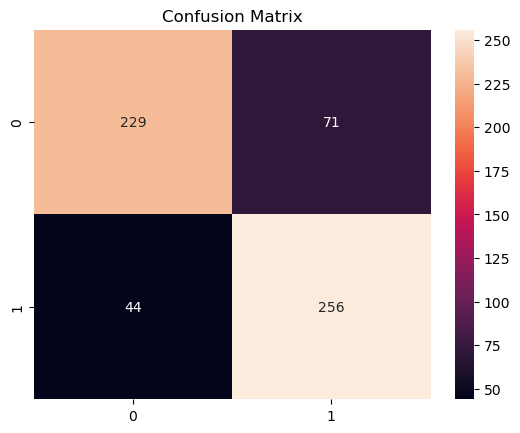

                    precision    recall  f1-score   support

      Non Demented       0.84      0.76      0.80       300
Very mild Dementia       0.78      0.85      0.82       300

          accuracy                           0.81       600
         macro avg       0.81      0.81      0.81       600
      weighted avg       0.81      0.81      0.81       600



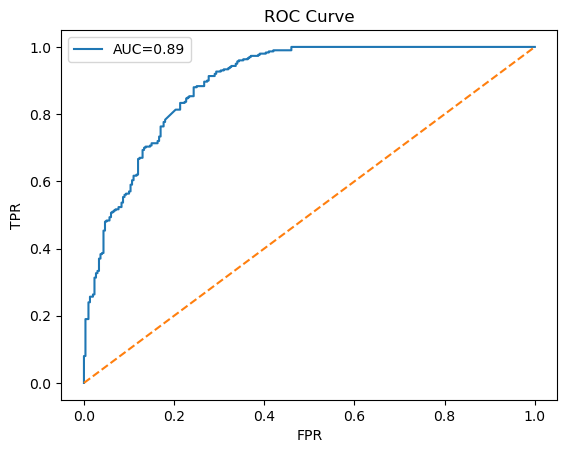

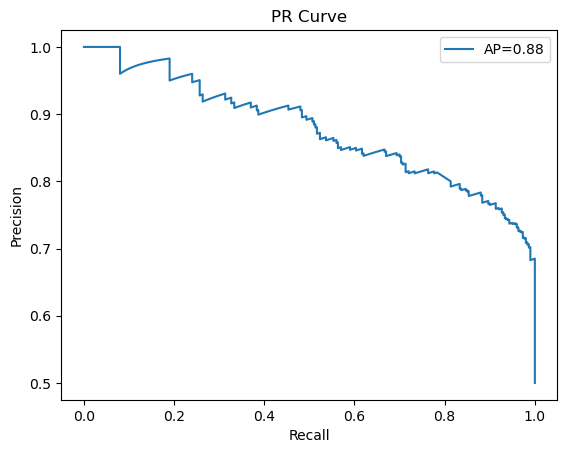

Sensitivity: 0.8533
Specificity: 0.7633
19/19 ━━━━━━━━━━━━━━━━━━━━ 14s 705ms/step
Total Inference Time: 23.214 sec
Time per Image: 0.03869 sec
Model Size: 112.94 MB


In [37]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import time

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense, Flatten, Dropout,
    Conv2D, MaxPooling2D, BatchNormalization
)
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

# =========================
# 1. PATH
# =========================
base_path = r"C:\Users\usER\Downloads\balanced_data"

categories = ['Non Demented', 'Very mild Dementia']

image_paths = []
labels = []

# =========================
# 2. LOAD DATA
# =========================
for category in categories:
    folder = os.path.join(base_path, category)
    for file in os.listdir(folder):
        image_paths.append(os.path.join(folder, file))
        labels.append(category)

df = pd.DataFrame({'image_path': image_paths, 'label': labels})

df['label'] = df['label'].map({
    'Non Demented': 0,
    'Very mild Dementia': 1
})

# =========================
# 3. SPLIT
# =========================
train_df, temp_df = train_test_split(
    df, test_size=0.3, stratify=df['label'], random_state=42
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['label'], random_state=42
)

print(len(train_df), len(val_df), len(test_df))

# =========================
# 4. AUGMENTATION
# =========================
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.15,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1./255)

# =========================
# 5. GENERATORS
# =========================
train_gen = train_datagen.flow_from_dataframe(
    train_df,
    x_col='image_path',
    y_col='label',
    target_size=(224,224),
    batch_size=32,
    class_mode='raw'
)

val_gen = val_datagen.flow_from_dataframe(
    val_df,
    x_col='image_path',
    y_col='label',
    target_size=(224,224),
    batch_size=32,
    class_mode='raw'
)

test_gen = val_datagen.flow_from_dataframe(
    test_df,
    x_col='image_path',
    y_col='label',
    target_size=(224,224),
    batch_size=32,
    class_mode='raw',
    shuffle=False
)

# =========================
# 6. CNN MODEL (FROM SCRATCH)
# =========================
model = Sequential([

    Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)),
    BatchNormalization(),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2,2),

    Conv2D(256, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2,2),

    Flatten(),

    Dense(256, activation='relu'),
    Dropout(0.5),

    Dense(128, activation='relu'),
    Dropout(0.3),

    Dense(1, activation='sigmoid')
])

# =========================
# 7. COMPILE
# =========================
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# =========================
# 8. TRAIN (20 EPOCHS)
# =========================
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20
)

# =========================
# 9. SAVE MODEL (.h5)
# =========================
model.save("cnn_model.h5")

# =========================
# 10. PLOTS
# =========================
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.legend()
plt.title("Accuracy")

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.legend()
plt.title("Loss")

plt.show()

# =========================
# 11. TEST
# =========================
test_loss, test_acc = model.evaluate(test_gen)
print("Test Accuracy:", test_acc)

# =========================
# 12. PREDICTIONS
# =========================
y_true = test_df['label'].values
y_probs = model.predict(test_gen)
y_pred = (y_probs > 0.5).astype(int)

# =========================
# 13. CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()

print(classification_report(
    y_true, y_pred,
    target_names=['Non Demented', 'Very mild Dementia']
))

# =========================
# 14. ROC CURVE
# =========================
fpr, tpr, _ = roc_curve(y_true, y_probs)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC={roc_auc:.2f}")
plt.plot([0,1],[0,1],'--')
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.title("ROC Curve")
plt.show()

# =========================
# 15. PR CURVE
# =========================
precision, recall, _ = precision_recall_curve(y_true, y_probs)
ap_score = average_precision_score(y_true, y_probs)

plt.plot(recall, precision, label=f"AP={ap_score:.2f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.title("PR Curve")
plt.show()

# =========================
# 16. SENSITIVITY & SPECIFICITY
# =========================
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

print("Sensitivity:", round(sensitivity, 4))
print("Specificity:", round(specificity, 4))

# =========================
# 17. INFERENCE TIME
# =========================
start = time.time()
_ = model.predict(test_gen)
end = time.time()

total_time = end - start
avg_time = total_time / len(test_df)

print("Total Inference Time:", round(total_time, 4), "sec")
print("Time per Image:", round(avg_time, 6), "sec")

# =========================
# 18. MODEL SIZE
# =========================
size_mb = os.path.getsize("cnn_model.h5") / (1024 * 1024)
print("Model Size:", round(size_mb, 2), "MB")

C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


2800 600 600
Found 2800 validated image filenames.
Found 600 validated image filenames.
Found 600 validated image filenames.


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


88/88 ━━━━━━━━━━━━━━━━━━━━ 333s 4s/step - accuracy: 0.5429 - loss: 1.1955 - val_accuracy: 0.5000 - val_loss: 1.5356
Epoch 2/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 316s 4s/step - accuracy: 0.6106 - loss: 0.6746 - val_accuracy: 0.5000 - val_loss: 2.3649
Epoch 3/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 313s 3s/step - accuracy: 0.6424 - loss: 0.6243 - val_accuracy: 0.5000 - val_loss: 1.5267
Epoch 4/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 306s 3s/step - accuracy: 0.6603 - loss: 0.5823 - val_accuracy: 0.5050 - val_loss: 0.9956
Epoch 5/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 313s 3s/step - accuracy: 0.6938 - loss: 0.5748 - val_accuracy: 0.5100 - val_loss: 1.0612
Epoch 6/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 320s 4s/step - accuracy: 0.6970 - loss: 0.5610 - val_accuracy: 0.5483 - val_loss: 0.7242
Epoch 7/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 344s 4s/step - accuracy: 0.7214 - loss: 0.5396 - val_accuracy: 0.7567 - val_loss: 0.5070
Epoch 8/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 279s 3s/step - accuracy: 0.7657 - loss: 0.5087 - val_accuracy: 0.7600 - val_loss: 0.

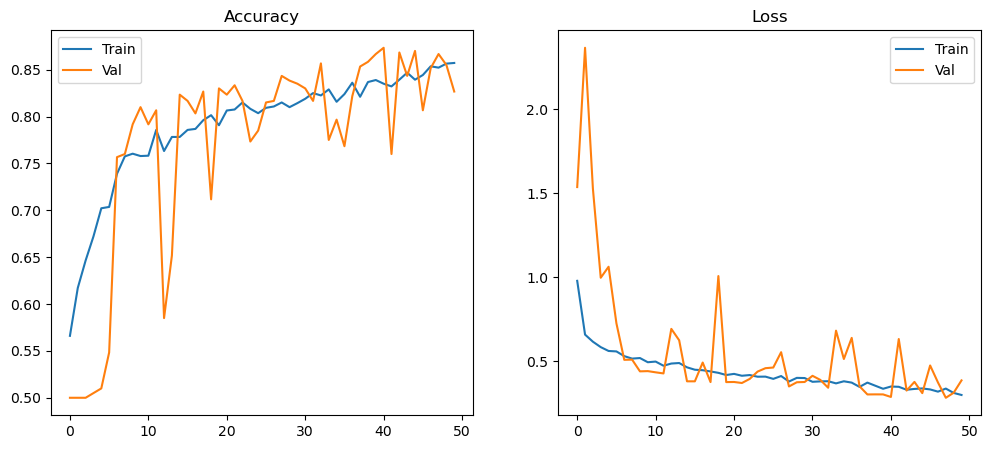

19/19 ━━━━━━━━━━━━━━━━━━━━ 12s 652ms/step - accuracy: 0.8260 - loss: 0.3995
Test Accuracy: 0.8316666483879089
19/19 ━━━━━━━━━━━━━━━━━━━━ 9s 463ms/step


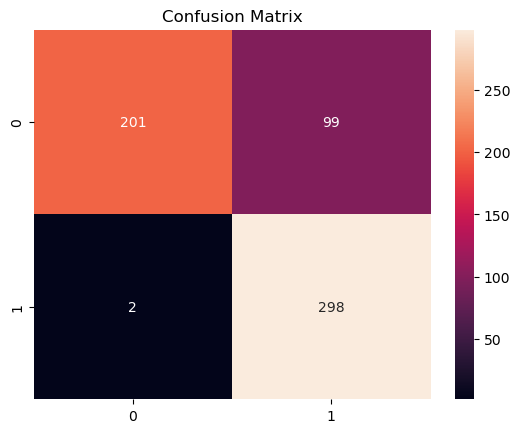

                    precision    recall  f1-score   support

      Non Demented       0.99      0.67      0.80       300
Very mild Dementia       0.75      0.99      0.86       300

          accuracy                           0.83       600
         macro avg       0.87      0.83      0.83       600
      weighted avg       0.87      0.83      0.83       600



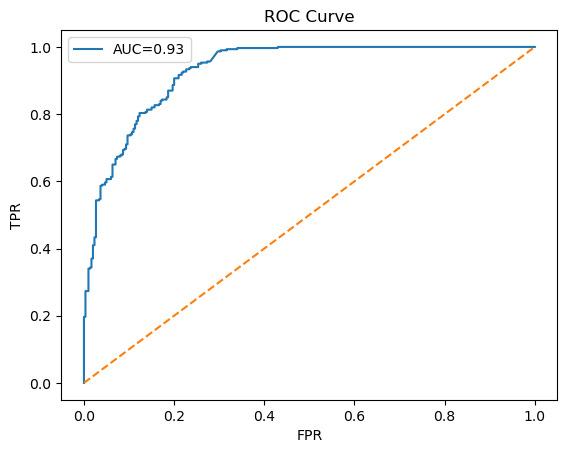

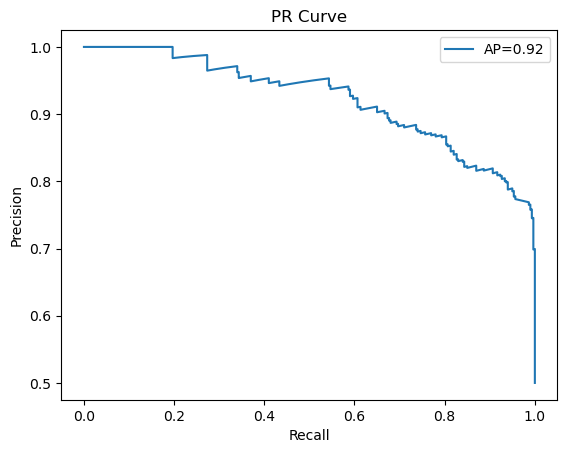

Sensitivity: 0.9933
Specificity: 0.67
19/19 ━━━━━━━━━━━━━━━━━━━━ 9s 462ms/step
Total Inference Time: 9.2299 sec
Time per Image: 0.015383 sec
Model Size: 112.93 MB


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import time

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense, Flatten, Dropout,
    Conv2D, MaxPooling2D, BatchNormalization
)
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

# =========================
# 1. PATH
# =========================
base_path = r"C:\Users\usER\Downloads\balanced_data"

categories = ['Non Demented', 'Very mild Dementia']

image_paths = []
labels = []

# =========================
# 2. LOAD DATA
# =========================
for category in categories:
    folder = os.path.join(base_path, category)
    for file in os.listdir(folder):
        image_paths.append(os.path.join(folder, file))
        labels.append(category)

df = pd.DataFrame({'image_path': image_paths, 'label': labels})

df['label'] = df['label'].map({
    'Non Demented': 0,
    'Very mild Dementia': 1
})

# =========================
# 3. SPLIT
# =========================
train_df, temp_df = train_test_split(
    df, test_size=0.3, stratify=df['label'], random_state=42
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['label'], random_state=42
)

print(len(train_df), len(val_df), len(test_df))

# =========================
# 4. AUGMENTATION
# =========================
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.15,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1./255)

# =========================
# 5. GENERATORS
# =========================
train_gen = train_datagen.flow_from_dataframe(
    train_df,
    x_col='image_path',
    y_col='label',
    target_size=(224,224),
    batch_size=32,
    class_mode='raw'
)

val_gen = val_datagen.flow_from_dataframe(
    val_df,
    x_col='image_path',
    y_col='label',
    target_size=(224,224),
    batch_size=32,
    class_mode='raw'
)

test_gen = val_datagen.flow_from_dataframe(
    test_df,
    x_col='image_path',
    y_col='label',
    target_size=(224,224),
    batch_size=32,
    class_mode='raw',
    shuffle=False
)

# =========================
# 6. CNN MODEL (FROM SCRATCH)
# =========================
model = Sequential([

    Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)),
    BatchNormalization(),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2,2),

    Conv2D(256, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2,2),

    Flatten(),

    Dense(256, activation='relu'),
    Dropout(0.5),

    Dense(128, activation='relu'),
    Dropout(0.3),

    Dense(1, activation='sigmoid')
])

# =========================
# 7. COMPILE
# =========================
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# =========================
# 8. TRAIN (20 EPOCHS)
# =========================
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=50
)

# =========================
# 9. SAVE MODEL (.h5)
# =========================
model.save("cnn_model.h5")

# =========================
# 10. PLOTS
# =========================
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.legend()
plt.title("Accuracy")

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.legend()
plt.title("Loss")

plt.show()

# =========================
# 11. TEST
# =========================
test_loss, test_acc = model.evaluate(test_gen)
print("Test Accuracy:", test_acc)

# =========================
# 12. PREDICTIONS
# =========================
y_true = test_df['label'].values
y_probs = model.predict(test_gen)
y_pred = (y_probs > 0.5).astype(int)

# =========================
# 13. CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()

print(classification_report(
    y_true, y_pred,
    target_names=['Non Demented', 'Very mild Dementia']
))

# =========================
# 14. ROC CURVE
# =========================
fpr, tpr, _ = roc_curve(y_true, y_probs)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC={roc_auc:.2f}")
plt.plot([0,1],[0,1],'--')
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.title("ROC Curve")
plt.show()

# =========================
# 15. PR CURVE
# =========================
precision, recall, _ = precision_recall_curve(y_true, y_probs)
ap_score = average_precision_score(y_true, y_probs)

plt.plot(recall, precision, label=f"AP={ap_score:.2f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.title("PR Curve")
plt.show()

# =========================
# 16. SENSITIVITY & SPECIFICITY
# =========================
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

print("Sensitivity:", round(sensitivity, 4))
print("Specificity:", round(specificity, 4))

# =========================
# 17. INFERENCE TIME
# =========================
start = time.time()
_ = model.predict(test_gen)
end = time.time()

total_time = end - start
avg_time = total_time / len(test_df)

print("Total Inference Time:", round(total_time, 4), "sec")
print("Time per Image:", round(avg_time, 6), "sec")

# =========================
# 18. MODEL SIZE
# =========================
size_mb = os.path.getsize("cnn_model.h5") / (1024 * 1024)
print("Model Size:", round(size_mb, 2), "MB")

2800 600 600
Found 2800 validated image filenames.
Found 600 validated image filenames.
Found 600 validated image filenames.
Epoch 1/20


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


88/88 ━━━━━━━━━━━━━━━━━━━━ 133s 1s/step - accuracy: 0.5414 - loss: 0.7541 - val_accuracy: 0.6417 - val_loss: 0.6452
Epoch 2/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 119s 1s/step - accuracy: 0.5977 - loss: 0.6700 - val_accuracy: 0.6650 - val_loss: 0.6267
Epoch 3/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 113s 1s/step - accuracy: 0.6457 - loss: 0.6415 - val_accuracy: 0.6900 - val_loss: 0.6099
Epoch 4/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 113s 1s/step - accuracy: 0.6600 - loss: 0.6227 - val_accuracy: 0.6733 - val_loss: 0.5980
Epoch 5/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 113s 1s/step - accuracy: 0.6504 - loss: 0.6158 - val_accuracy: 0.7250 - val_loss: 0.5655
Epoch 6/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 114s 1s/step - accuracy: 0.6651 - loss: 0.6090 - val_accuracy: 0.7333 - val_loss: 0.5539
Epoch 7/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 113s 1s/step - accuracy: 0.6891 - loss: 0.5849 - val_accuracy: 0.7183 - val_loss: 0.5424
Epoch 8/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 113s 1s/step - accuracy: 0.6826 - loss: 0.5865 - val_accuracy: 0.7333 - val_loss: 0.

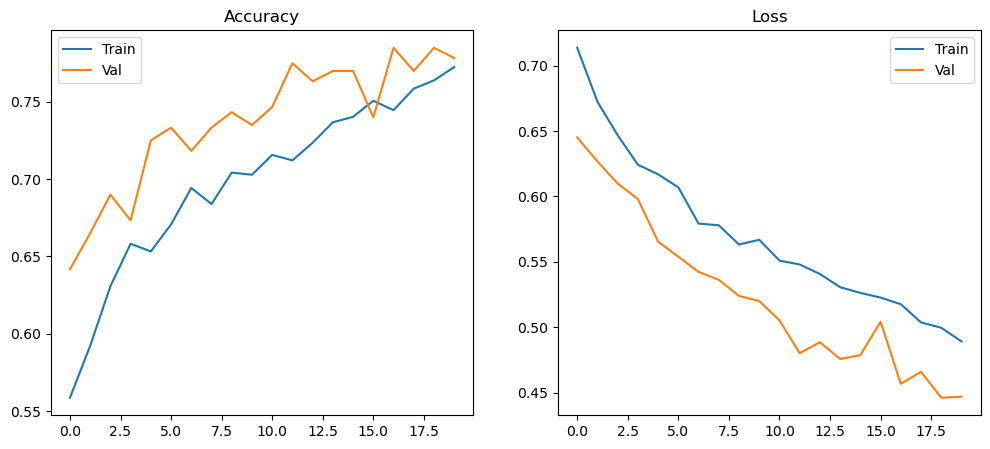

19/19 ━━━━━━━━━━━━━━━━━━━━ 14s 749ms/step - accuracy: 0.8292 - loss: 0.4068
Test Accuracy: 0.8100000023841858
19/19 ━━━━━━━━━━━━━━━━━━━━ 21s 963ms/step


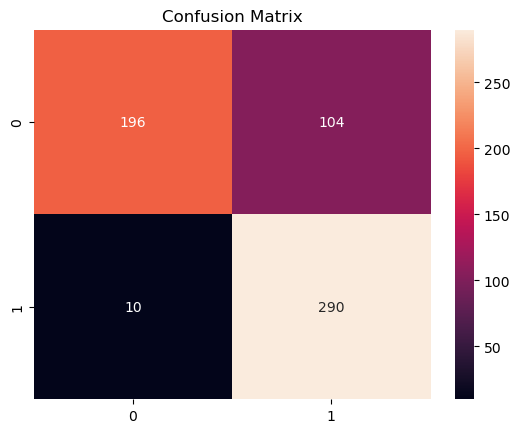

                    precision    recall  f1-score   support

      Non Demented       0.95      0.65      0.77       300
Very mild Dementia       0.74      0.97      0.84       300

          accuracy                           0.81       600
         macro avg       0.84      0.81      0.81       600
      weighted avg       0.84      0.81      0.81       600



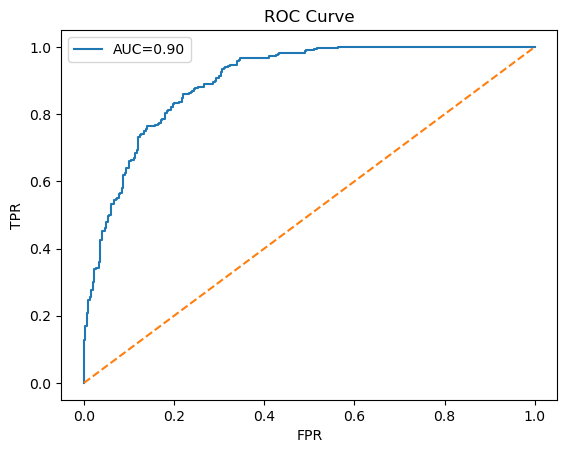

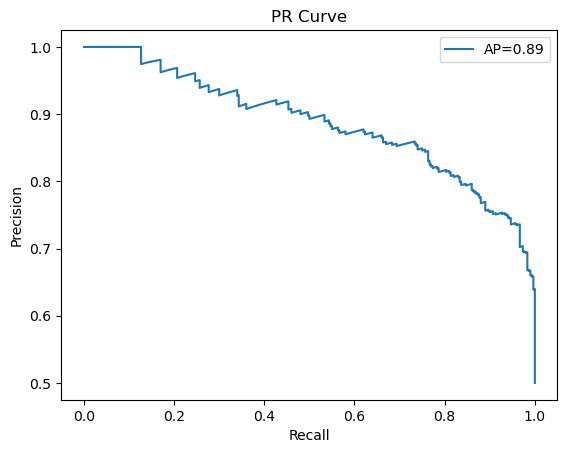

Sensitivity: 0.9667
Specificity: 0.6533
19/19 ━━━━━━━━━━━━━━━━━━━━ 15s 772ms/step
Total Inference Time: 15.2465 sec
Time per Image: 0.025411 sec
Model Size: 22.78 MB


In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import time

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

# =========================
# 1. PATH
# =========================
base_path = r"C:\Users\usER\Downloads\balanced_data"

categories = ['Non Demented', 'Very mild Dementia']

image_paths = []
labels = []

# =========================
# 2. LOAD DATA
# =========================
for category in categories:
    folder = os.path.join(base_path, category)
    for file in os.listdir(folder):
        image_paths.append(os.path.join(folder, file))
        labels.append(category)

df = pd.DataFrame({'image_path': image_paths, 'label': labels})

df['label'] = df['label'].map({
    'Non Demented': 0,
    'Very mild Dementia': 1
})

# =========================
# 3. SPLIT
# =========================
train_df, temp_df = train_test_split(
    df, test_size=0.3, stratify=df['label'], random_state=42
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['label'], random_state=42
)

print(len(train_df), len(val_df), len(test_df))

# =========================
# 4. AUGMENTATION
# =========================
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.15,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1./255)

# =========================
# 5. GENERATORS
# =========================
train_gen = train_datagen.flow_from_dataframe(
    train_df,
    x_col='image_path',
    y_col='label',
    target_size=(224,224),
    batch_size=32,
    class_mode='raw'
)

val_gen = val_datagen.flow_from_dataframe(
    val_df,
    x_col='image_path',
    y_col='label',
    target_size=(224,224),
    batch_size=32,
    class_mode='raw'
)

test_gen = val_datagen.flow_from_dataframe(
    test_df,
    x_col='image_path',
    y_col='label',
    target_size=(224,224),
    batch_size=32,
    class_mode='raw',
    shuffle=False
)

# =========================
# 6. MOBILENETV2 MODEL
# =========================
base_model = MobileNetV2(
    input_shape=(224,224,3),
    include_top=False,
    weights='imagenet'
)

# Freeze base model
for layer in base_model.layers:
    layer.trainable = False

# Custom head
x = base_model.output
x = GlobalAveragePooling2D()(x)

x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)

x = Dense(64, activation='relu')(x)
x = Dropout(0.3)(x)

output = Dense(1, activation='sigmoid')(x)

model = tf.keras.models.Model(inputs=base_model.input, outputs=output)

# =========================
# 7. COMPILE
# =========================
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# =========================
# 8. TRAIN
# =========================
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20
)

# =========================
# 9. FINE-TUNING
# =========================
for layer in base_model.layers[-30:]:
    layer.trainable = True

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_fine = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10
)

# =========================
# 10. SAVE MODEL
# =========================
model.save("mobilenetv2_model.h5")

# =========================
# 11. PLOTS
# =========================
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.legend()
plt.title("Accuracy")

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.legend()
plt.title("Loss")

plt.show()

# =========================
# 12. TEST
# =========================
test_loss, test_acc = model.evaluate(test_gen)
print("Test Accuracy:", test_acc)

# =========================
# 13. PREDICTIONS
# =========================
y_true = test_df['label'].values
y_probs = model.predict(test_gen)
y_pred = (y_probs > 0.5).astype(int)

# =========================
# 14. CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()

print(classification_report(
    y_true, y_pred,
    target_names=['Non Demented', 'Very mild Dementia']
))

# =========================
# 15. ROC CURVE
# =========================
fpr, tpr, _ = roc_curve(y_true, y_probs)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC={roc_auc:.2f}")
plt.plot([0,1],[0,1],'--')
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.title("ROC Curve")
plt.show()

# =========================
# 16. PR CURVE
# =========================
precision, recall, _ = precision_recall_curve(y_true, y_probs)
ap_score = average_precision_score(y_true, y_probs)

plt.plot(recall, precision, label=f"AP={ap_score:.2f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.title("PR Curve")
plt.show()

# =========================
# 17. SENSITIVITY & SPECIFICITY
# =========================
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

print("Sensitivity:", round(sensitivity, 4))
print("Specificity:", round(specificity, 4))

# =========================
# 18. INFERENCE TIME
# =========================
start = time.time()
_ = model.predict(test_gen)
end = time.time()

total_time = end - start
avg_time = total_time / len(test_df)

print("Total Inference Time:", round(total_time, 4), "sec")
print("Time per Image:", round(avg_time, 6), "sec")

# =========================
# 19. MODEL SIZE
# =========================
size_mb = os.path.getsize("mobilenetv2_model.h5") / (1024 * 1024)
print("Model Size:", round(size_mb, 2), "MB")

2800 600 600
Found 2800 validated image filenames.
Found 600 validated image filenames.
Found 600 validated image filenames.
Epoch 1/50


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


88/88 ━━━━━━━━━━━━━━━━━━━━ 168s 2s/step - accuracy: 0.5158 - loss: 0.7779 - val_accuracy: 0.4867 - val_loss: 0.7230
Epoch 2/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 208s 2s/step - accuracy: 0.5593 - loss: 0.7040 - val_accuracy: 0.5233 - val_loss: 0.6977
Epoch 3/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 160s 2s/step - accuracy: 0.5723 - loss: 0.6871 - val_accuracy: 0.5650 - val_loss: 0.6772
Epoch 4/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 181s 2s/step - accuracy: 0.6174 - loss: 0.6543 - val_accuracy: 0.6233 - val_loss: 0.6564
Epoch 5/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 152s 2s/step - accuracy: 0.6351 - loss: 0.6308 - val_accuracy: 0.6283 - val_loss: 0.6378
Epoch 6/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 136s 1s/step - accuracy: 0.6581 - loss: 0.6048 - val_accuracy: 0.6700 - val_loss: 0.6148
Epoch 7/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 135s 1s/step - accuracy: 0.6869 - loss: 0.5824 - val_accuracy: 0.6967 - val_loss: 0.5956
Epoch 8/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 148s 2s/step - accuracy: 0.7040 - loss: 0.5783 - val_accuracy: 0.7300 - val_loss: 0.

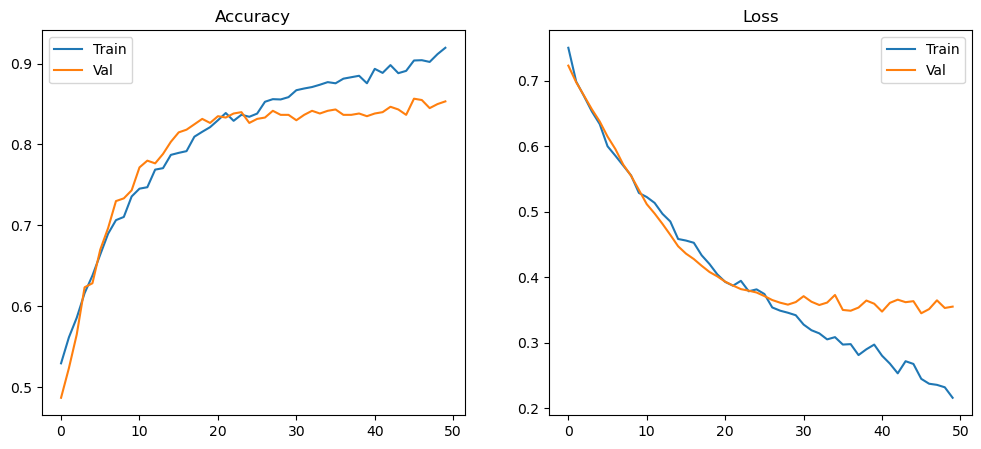

19/19 ━━━━━━━━━━━━━━━━━━━━ 14s 739ms/step - accuracy: 0.8487 - loss: 0.3279
Test Accuracy: 0.8416666388511658
19/19 ━━━━━━━━━━━━━━━━━━━━ 18s 818ms/step


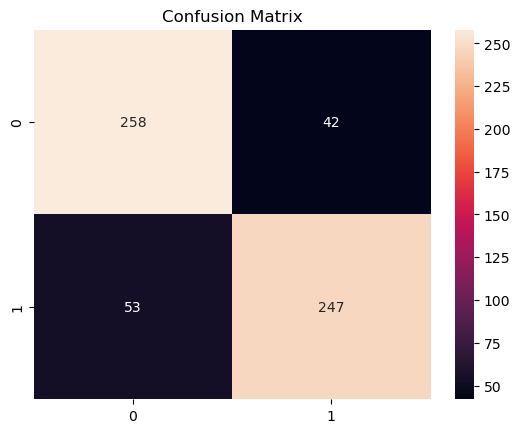

                    precision    recall  f1-score   support

      Non Demented       0.83      0.86      0.84       300
Very mild Dementia       0.85      0.82      0.84       300

          accuracy                           0.84       600
         macro avg       0.84      0.84      0.84       600
      weighted avg       0.84      0.84      0.84       600



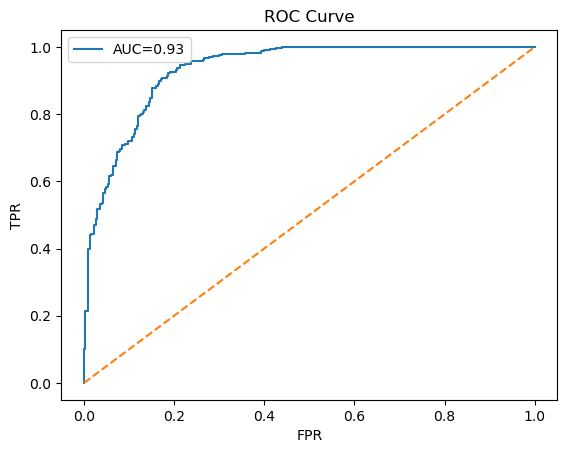

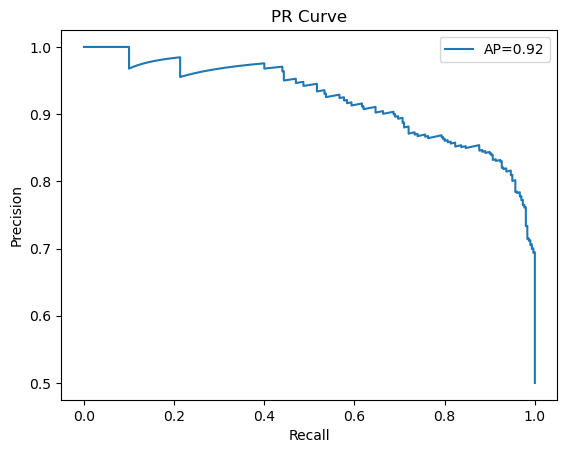

Sensitivity: 0.8233
Specificity: 0.86
19/19 ━━━━━━━━━━━━━━━━━━━━ 14s 720ms/step
Total Inference Time: 13.9935 sec
Time per Image: 0.023322 sec
Model Size: 22.78 MB


In [4]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import time

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

# =========================
# 1. PATH
# =========================
base_path = r"C:\Users\usER\Downloads\balanced_data"

categories = ['Non Demented', 'Very mild Dementia']

image_paths = []
labels = []

# =========================
# 2. LOAD DATA
# =========================
for category in categories:
    folder = os.path.join(base_path, category)
    for file in os.listdir(folder):
        image_paths.append(os.path.join(folder, file))
        labels.append(category)

df = pd.DataFrame({'image_path': image_paths, 'label': labels})

df['label'] = df['label'].map({
    'Non Demented': 0,
    'Very mild Dementia': 1
})

# =========================
# 3. SPLIT
# =========================
train_df, temp_df = train_test_split(
    df, test_size=0.3, stratify=df['label'], random_state=42
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['label'], random_state=42
)

print(len(train_df), len(val_df), len(test_df))

# =========================
# 4. AUGMENTATION
# =========================
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.15,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1./255)

# =========================
# 5. GENERATORS
# =========================
train_gen = train_datagen.flow_from_dataframe(
    train_df,
    x_col='image_path',
    y_col='label',
    target_size=(224,224),
    batch_size=32,
    class_mode='raw'
)

val_gen = val_datagen.flow_from_dataframe(
    val_df,
    x_col='image_path',
    y_col='label',
    target_size=(224,224),
    batch_size=32,
    class_mode='raw'
)

test_gen = val_datagen.flow_from_dataframe(
    test_df,
    x_col='image_path',
    y_col='label',
    target_size=(224,224),
    batch_size=32,
    class_mode='raw',
    shuffle=False
)

# =========================
# 6. MOBILENETV2 MODEL (ONE TRAINING)
# =========================
base_model = MobileNetV2(
    input_shape=(224,224,3),
    include_top=False,
    weights='imagenet'
)

# Freeze most layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Unfreeze last layers
for layer in base_model.layers[-30:]:
    layer.trainable = True

# Custom head
x = base_model.output
x = GlobalAveragePooling2D()(x)

x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)

x = Dense(64, activation='relu')(x)
x = Dropout(0.3)(x)

output = Dense(1, activation='sigmoid')(x)

model = tf.keras.models.Model(inputs=base_model.input, outputs=output)

# =========================
# 7. COMPILE
# =========================
model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# =========================
# 8. TRAIN (50 EPOCHS ONLY)
# =========================
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=50,
    callbacks=[early_stop]
)

# =========================
# 9. SAVE MODEL
# =========================
model.save("mobilenetv2_model.h5")

# =========================
# 10. PLOTS
# =========================
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.legend()
plt.title("Accuracy")

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.legend()
plt.title("Loss")

plt.show()

# =========================
# 11. TEST
# =========================
test_loss, test_acc = model.evaluate(test_gen)
print("Test Accuracy:", test_acc)

# =========================
# 12. PREDICTIONS
# =========================
y_true = test_df['label'].values
y_probs = model.predict(test_gen)
y_pred = (y_probs > 0.5).astype(int)

# =========================
# 13. CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()

print(classification_report(
    y_true, y_pred,
    target_names=['Non Demented', 'Very mild Dementia']
))

# =========================
# 14. ROC CURVE
# =========================
fpr, tpr, _ = roc_curve(y_true, y_probs)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC={roc_auc:.2f}")
plt.plot([0,1],[0,1],'--')
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.title("ROC Curve")
plt.show()

# =========================
# 15. PR CURVE
# =========================
precision, recall, _ = precision_recall_curve(y_true, y_probs)
ap_score = average_precision_score(y_true, y_probs)

plt.plot(recall, precision, label=f"AP={ap_score:.2f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.title("PR Curve")
plt.show()

# =========================
# 16. SENSITIVITY & SPECIFICITY
# =========================
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

print("Sensitivity:", round(sensitivity, 4))
print("Specificity:", round(specificity, 4))

# =========================
# 17. INFERENCE TIME
# =========================
start = time.time()
_ = model.predict(test_gen)
end = time.time()

total_time = end - start
avg_time = total_time / len(test_df)

print("Total Inference Time:", round(total_time, 4), "sec")
print("Time per Image:", round(avg_time, 6), "sec")

# =========================
# 18. MODEL SIZE
# =========================
size_mb = os.path.getsize("mobilenetv2_model.h5") / (1024 * 1024)
print("Model Size:", round(size_mb, 2), "MB")

2800 600 600
Found 2800 validated image filenames.
Found 600 validated image filenames.
Found 600 validated image filenames.
Epoch 1/50


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


88/88 ━━━━━━━━━━━━━━━━━━━━ 1064s 12s/step - accuracy: 0.5586 - loss: 0.7221 - val_accuracy: 0.7167 - val_loss: 0.5685
Epoch 2/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1053s 12s/step - accuracy: 0.6722 - loss: 0.6180 - val_accuracy: 0.7783 - val_loss: 0.4742
Epoch 3/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1059s 12s/step - accuracy: 0.7637 - loss: 0.5115 - val_accuracy: 0.7800 - val_loss: 0.4744
Epoch 4/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1049s 12s/step - accuracy: 0.7803 - loss: 0.4885 - val_accuracy: 0.7883 - val_loss: 0.4721
Epoch 5/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1048s 12s/step - accuracy: 0.8077 - loss: 0.4206 - val_accuracy: 0.8517 - val_loss: 0.3823
Epoch 6/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1052s 12s/step - accuracy: 0.8102 - loss: 0.4137 - val_accuracy: 0.8450 - val_loss: 0.3655
Epoch 7/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1059s 12s/step - accuracy: 0.8443 - loss: 0.3562 - val_accuracy: 0.8067 - val_loss: 0.4159
Epoch 8/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1050s 12s/step - accuracy: 0.8538 - loss: 0.3514 - val_accuracy: 0.866

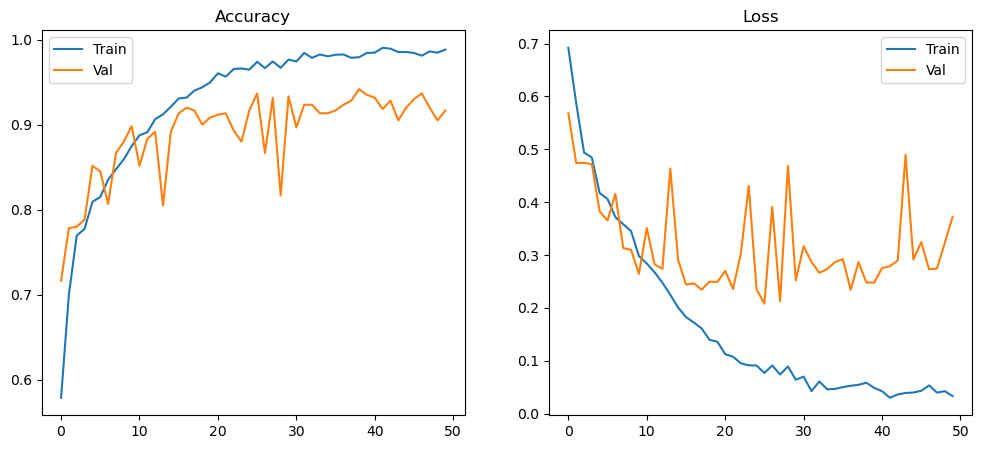

19/19 ━━━━━━━━━━━━━━━━━━━━ 161s 8s/step - accuracy: 0.9072 - loss: 0.4840
Test Accuracy: 0.903333306312561
19/19 ━━━━━━━━━━━━━━━━━━━━ 161s 8s/step


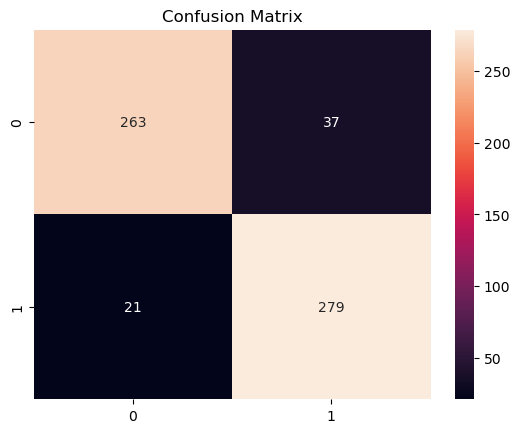

              precision    recall  f1-score   support

           0       0.93      0.88      0.90       300
           1       0.88      0.93      0.91       300

    accuracy                           0.90       600
   macro avg       0.90      0.90      0.90       600
weighted avg       0.90      0.90      0.90       600



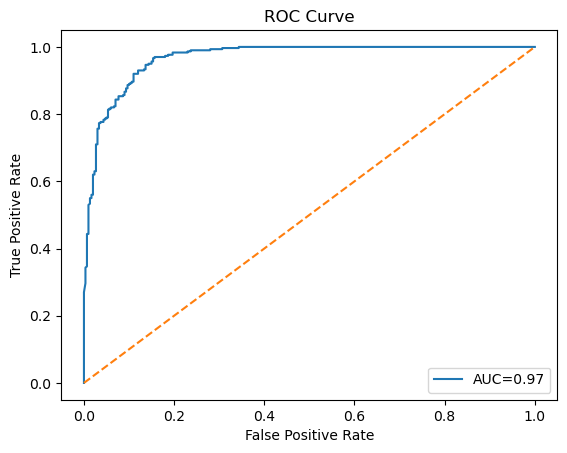

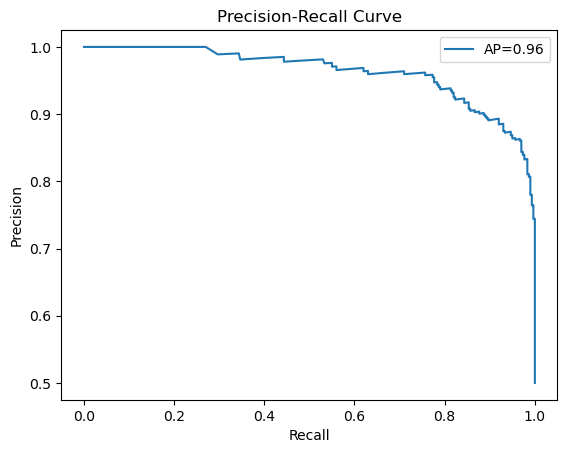

Sensitivity: 0.93
Specificity: 0.8767
19/19 ━━━━━━━━━━━━━━━━━━━━ 163s 9s/step
Total Inference Time: 163.5978 sec
Time per Image: 0.272663 sec
Model Size: 184.11 MB


In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import time

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

# =========================
# 1. PATH
# =========================
base_path = r"C:\Users\usER\Downloads\balanced_data"

categories = ['Non Demented', 'Very mild Dementia']

image_paths = []
labels = []

# =========================
# 2. LOAD DATA
# =========================
for category in categories:
    folder = os.path.join(base_path, category)
    for file in os.listdir(folder):
        image_paths.append(os.path.join(folder, file))
        labels.append(category)

df = pd.DataFrame({'image_path': image_paths, 'label': labels})

df['label'] = df['label'].map({
    'Non Demented': 0,
    'Very mild Dementia': 1
})

# =========================
# 3. SPLIT
# =========================
train_df, temp_df = train_test_split(
    df, test_size=0.3, stratify=df['label'], random_state=42
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['label'], random_state=42
)

print(len(train_df), len(val_df), len(test_df))

# =========================
# 4. AUGMENTATION
# =========================
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.15,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1./255)

# =========================
# 5. GENERATORS
# =========================
train_gen = train_datagen.flow_from_dataframe(
    train_df,
    x_col='image_path',
    y_col='label',
    target_size=(224,224),
    batch_size=32,
    class_mode='raw'
)

val_gen = val_datagen.flow_from_dataframe(
    val_df,
    x_col='image_path',
    y_col='label',
    target_size=(224,224),
    batch_size=32,
    class_mode='raw'
)

test_gen = val_datagen.flow_from_dataframe(
    test_df,
    x_col='image_path',
    y_col='label',
    target_size=(224,224),
    batch_size=32,
    class_mode='raw',
    shuffle=False
)

# =========================
# 6. MODEL
# =========================
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224,224,3))

for layer in base_model.layers[:-4]:
    layer.trainable = False

model = Sequential([
    base_model,
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

# =========================
# 7. COMPILE
# =========================
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# =========================
# 8. TRAIN (20 EPOCHS)
# =========================
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=50
)

# =========================
# 9. SAVE MODEL (.h5)
# =========================
model.save("vgg16_model.h5")

# =========================
# 10. PLOTS
# =========================
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.legend()
plt.title("Accuracy")

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.legend()
plt.title("Loss")

plt.show()

# =========================
# 11. TEST
# =========================
test_loss, test_acc = model.evaluate(test_gen)
print("Test Accuracy:", test_acc)

# =========================
# 12. PREDICTIONS
# =========================
y_true = test_df['label'].values
y_probs = model.predict(test_gen)
y_pred = (y_probs > 0.5).astype(int)

# =========================
# 13. CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()

print(classification_report(y_true, y_pred))

# =========================
# 14. ROC CURVE
# =========================
fpr, tpr, _ = roc_curve(y_true, y_probs)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC={roc_auc:.2f}")
plt.plot([0,1],[0,1],'--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.title("ROC Curve")
plt.show()

# =========================
# 15. PR CURVE
# =========================
precision, recall, _ = precision_recall_curve(y_true, y_probs)
ap_score = average_precision_score(y_true, y_probs)

plt.plot(recall, precision, label=f"AP={ap_score:.2f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.title("Precision-Recall Curve")
plt.show()

# =========================
# 16. SENSITIVITY & SPECIFICITY
# =========================
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

print("Sensitivity:", round(sensitivity, 4))
print("Specificity:", round(specificity, 4))

# =========================
# 17. INFERENCE TIME
# =========================
start = time.time()
_ = model.predict(test_gen)
end = time.time()

total_time = end - start
avg_time = total_time / len(test_df)

print("Total Inference Time:", round(total_time, 4), "sec")
print("Time per Image:", round(avg_time, 6), "sec")

# =========================
# 18. MODEL SIZE
# =========================
size_mb = os.path.getsize("vgg16_model.h5") / (1024 * 1024)
print("Model Size:", round(size_mb, 2), "MB")

In [576]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

model = tf.keras.models.load_model("vgg16_model.h5")
base_model = model.layers[0]

In [577]:
def preprocess_image(path):
    img = tf.keras.preprocessing.image.load_img(path, target_size=(224,224))
    img = tf.keras.preprocessing.image.img_to_array(img)
    img = np.expand_dims(img, axis=0)
    return img / 255.0

In [578]:
def gradcam(img_array):

    conv_layer = base_model.get_layer("block5_conv3")

    conv_model = tf.keras.models.Model(
        inputs=base_model.input,
        outputs=conv_layer.output
    )

    conv_outputs = conv_model(img_array)

    with tf.GradientTape() as tape:
        tape.watch(conv_outputs)
        preds = model(img_array)
        loss = preds[:, 0]

    grads = tape.gradient(loss, conv_outputs)

    if grads is None:
        grads = tf.ones_like(conv_outputs)

    # 🔥 normalize gradients (IMPORTANT FIX)
    grads = tf.nn.softmax(grads)

    pooled = tf.reduce_mean(grads, axis=(0,1,2))

    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.nn.relu(heatmap)

    # 🔥 STRONG CONTRAST FIX
    heatmap = heatmap - tf.reduce_min(heatmap)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy()

In [579]:
def show(img_path, heatmap):

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224,224))

    heatmap = cv2.resize(heatmap, (224,224))

    # 🔥 INVERT IMPORTANCE
    heatmap = 1 - heatmap

    heatmap = np.uint8(255 * heatmap)

    # 🎨 COLOR CONTROL HERE
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    heatmap = cv2.GaussianBlur(heatmap, (5,5), 0)

    output = cv2.addWeighted(img, 0.6, heatmap, 0.5, 0)

    plt.imshow(output)
    plt.axis("off")
    plt.show()

Prediction: 2.2565407e-12
Class: Non Demented


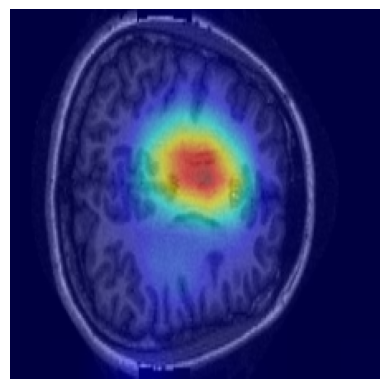

In [580]:
img_path = r"C:\Users\usER\Downloads\balanced_data\Non Demented\OAS1_0140_MR1_mpr-1_142.jpg"

img_array = preprocess_image(img_path)

pred = model.predict(img_array, verbose=0)[0][0]

print("Prediction:", pred)
print("Class:", "Very mild Dementia" if pred > 0.5 else "Non Demented")

heatmap = gradcam(img_array)

show(img_path, heatmap)

In [581]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("Libraries loaded successfully.")

TensorFlow version: 2.17.0
Libraries loaded successfully.


In [582]:
model = tf.keras.models.load_model("vgg16_model.h5")

print("Model loaded successfully.")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

Model loaded successfully.
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)


In [583]:
base_model = model.layers[0]

print("Base model:", base_model.name)
print("Base model output shape:", base_model.output_shape)

Base model: vgg16
Base model output shape: (None, 7, 7, 512)


In [584]:
target_layer = base_model.get_layer("block5_conv3")

print("Grad-CAM layer:", target_layer.name)
print("Number of filters:", target_layer.filters)

Grad-CAM layer: block5_conv3
Number of filters: 512


In [585]:
def preprocess_image(path):
    img = tf.keras.preprocessing.image.load_img(
        path,
        target_size=(224, 224)
    )

    img = tf.keras.preprocessing.image.img_to_array(img)

    img = np.expand_dims(img, axis=0)

    img = img / 255.0

    return img

In [586]:
img_path = r"C:\Users\usER\Downloads\balanced_data\Non Demented\OAS1_0140_MR1_mpr-1_142.jpg"

img_array = preprocess_image(img_path)

print("Image prepared successfully.")
print("Image shape:", img_array.shape)
print("Minimum pixel value:", img_array.min())
print("Maximum pixel value:", img_array.max())

Image prepared successfully.
Image shape: (1, 224, 224, 3)
Minimum pixel value: 0.0
Maximum pixel value: 0.9764706


In [587]:
prediction = model.predict(img_array, verbose=0)

probability = float(prediction[0][0])

print("Prediction probability:", probability)

if probability >= 0.5:
    predicted_class = "Very mild Dementia"
else:
    predicted_class = "Non Demented"

print("Predicted class:", predicted_class)

Prediction probability: 2.256540657455397e-12
Predicted class: Non Demented


In [588]:
def gradcam(img_array):

    target_layer = base_model.get_layer("block5_conv3")

    # Model that returns the target convolutional activations
    # and the VGG16 feature output
    grad_model = tf.keras.models.Model(
        inputs=base_model.input,
        outputs=[target_layer.output, base_model.output]
    )

    with tf.GradientTape() as tape:

        conv_outputs, base_output = grad_model(
            img_array,
            training=False
        )

        # Pass VGG16 features through the classifier
        x = base_output

        for layer in model.layers[1:]:
            x = layer(x, training=False)

        predictions = x[:, 0]

        # Explain the predicted class
        if float(predictions[0]) >= 0.5:
            target = predictions
        else:
            target = 1.0 - predictions

    # Gradient of target class with respect to feature maps
    grads = tape.gradient(target, conv_outputs)

    # Global average pooling
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    # Remove batch dimension
    conv_outputs = conv_outputs[0]

    # Weighted combination of feature maps
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    # ReLU
    heatmap = tf.maximum(heatmap, 0)

    # Normalize ONLY for visualization
    max_value = tf.reduce_max(heatmap)

    heatmap = heatmap / (
        max_value + tf.keras.backend.epsilon()
    )

    return heatmap.numpy()

In [589]:
heatmap = gradcam(img_array)

print("Heatmap generated successfully.")
print("Heatmap shape:", heatmap.shape)
print("Heatmap minimum:", heatmap.min())
print("Heatmap maximum:", heatmap.max())

Heatmap generated successfully.
Heatmap shape: (14, 14)
Heatmap minimum: 0.0
Heatmap maximum: 2.6308064e-06


In [590]:
def show_gradcam(img_path, heatmap):

    # Load original image
    original = cv2.imread(img_path)
    original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
    original = cv2.resize(original, (224, 224))

    # Resize Grad-CAM
    heatmap_resized = cv2.resize(
        heatmap,
        (224, 224),
        interpolation=cv2.INTER_LINEAR
    )

    # Convert heatmap to 0–255
    heatmap_uint8 = np.uint8(255 * heatmap_resized)

    # Apply JET colormap
    heatmap_color = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    # Convert BGR to RGB
    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    # Create overlay
    overlay = cv2.addWeighted(
        original,
        0.6,
        heatmap_color,
        0.4,
        0
    )

    # Create figure
    plt.figure(figsize=(15, 5))

    # Original
    plt.subplot(1, 3, 1)
    plt.imshow(original)
    plt.title("Original Image", fontsize=14)
    plt.axis("off")

    # Heatmap
    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title("Grad-CAM Heatmap", fontsize=14)
    plt.axis("off")

    # Overlay
    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    plt.title("Grad-CAM Overlay", fontsize=14)
    plt.axis("off")

    plt.tight_layout()
    plt.show()

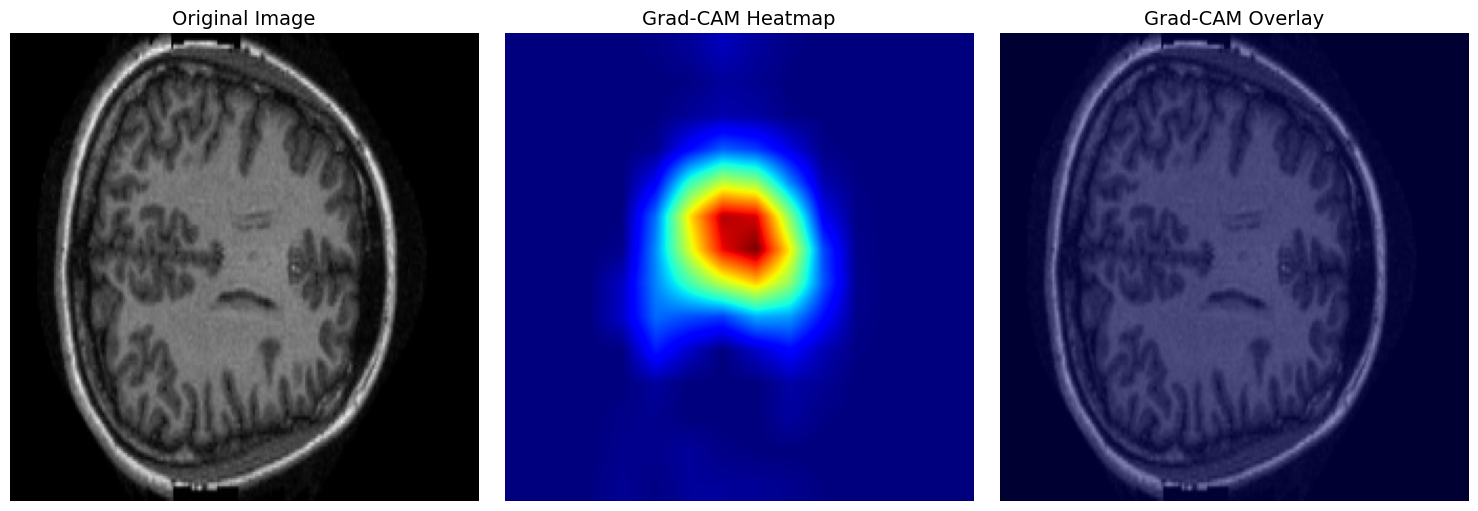

In [591]:
show_gradcam(img_path, heatmap)

C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


2800 600 600
Found 2800 validated image filenames.
Found 600 validated image filenames.
Found 600 validated image filenames.
Epoch 1/50


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


88/88 ━━━━━━━━━━━━━━━━━━━━ 469s 5s/step - accuracy: 0.5962 - loss: 0.6590 - val_accuracy: 0.7967 - val_loss: 0.4764
Epoch 2/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 482s 5s/step - accuracy: 0.7545 - loss: 0.4995 - val_accuracy: 0.8267 - val_loss: 0.4032
Epoch 3/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 441s 5s/step - accuracy: 0.8214 - loss: 0.3971 - val_accuracy: 0.8300 - val_loss: 0.3738
Epoch 4/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 511s 6s/step - accuracy: 0.8422 - loss: 0.3648 - val_accuracy: 0.8383 - val_loss: 0.3661
Epoch 5/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 545s 6s/step - accuracy: 0.8508 - loss: 0.3611 - val_accuracy: 0.8383 - val_loss: 0.3605
Epoch 6/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 537s 6s/step - accuracy: 0.8600 - loss: 0.3282 - val_accuracy: 0.8083 - val_loss: 0.4329
Epoch 7/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 554s 6s/step - accuracy: 0.8715 - loss: 0.2998 - val_accuracy: 0.8717 - val_loss: 0.3035
Epoch 8/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 532s 6s/step - accuracy: 0.8808 - loss: 0.2824 - val_accuracy: 0.8550 - val_loss: 0.

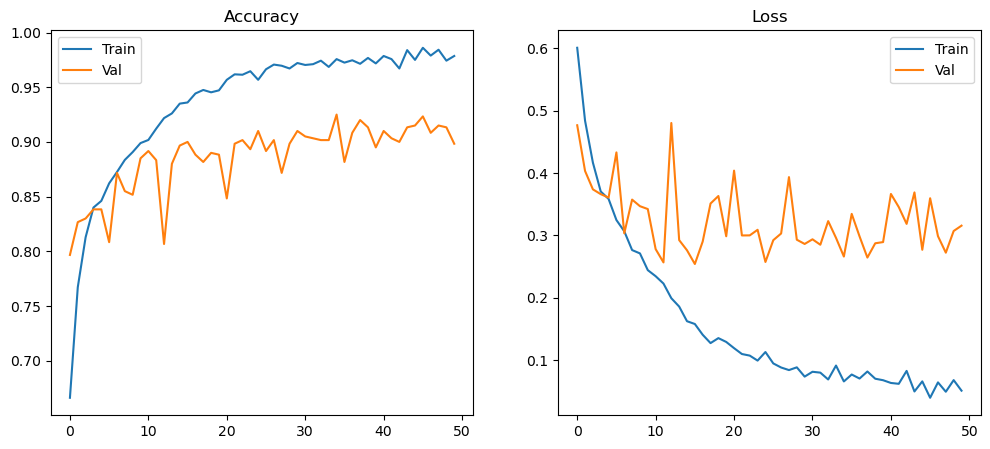

19/19 ━━━━━━━━━━━━━━━━━━━━ 68s 4s/step - accuracy: 0.8718 - loss: 0.4430
Test Accuracy: 0.8999999761581421
19/19 ━━━━━━━━━━━━━━━━━━━━ 73s 4s/step


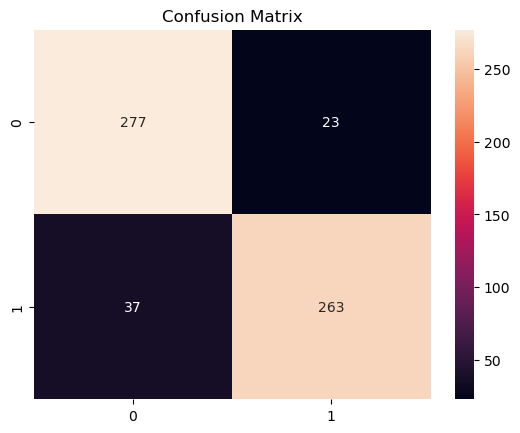

              precision    recall  f1-score   support

           0       0.88      0.92      0.90       300
           1       0.92      0.88      0.90       300

    accuracy                           0.90       600
   macro avg       0.90      0.90      0.90       600
weighted avg       0.90      0.90      0.90       600



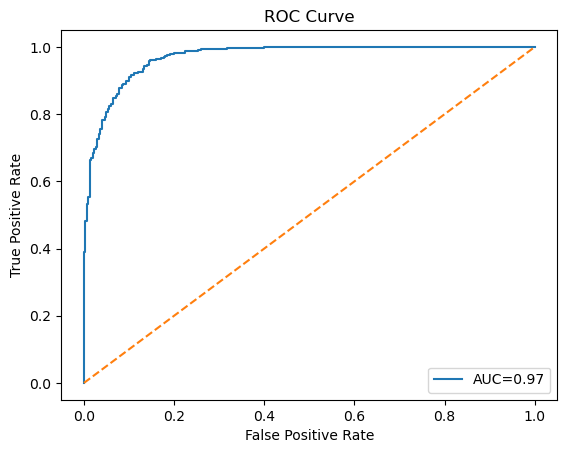

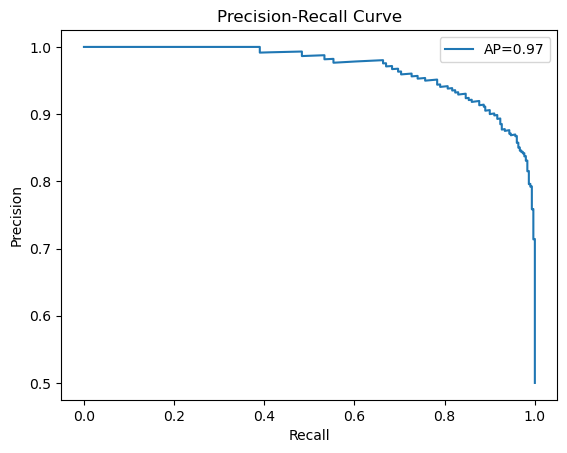

Sensitivity: 0.8767
Specificity: 0.9233
19/19 ━━━━━━━━━━━━━━━━━━━━ 67s 4s/step
Total Inference Time: 67.4646 sec
Time per Image: 0.112441 sec
Model Size: 129.51 MB


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import time

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.applications.inception_v3 import preprocess_input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

# =========================
# 1. PATH
# =========================
base_path = r"C:\Users\usER\Downloads\balanced_data"

categories = ['Non Demented', 'Very mild Dementia']

image_paths = []
labels = []

# =========================
# 2. LOAD DATA
# =========================
for category in categories:
    folder = os.path.join(base_path, category)
    for file in os.listdir(folder):
        image_paths.append(os.path.join(folder, file))
        labels.append(category)

df = pd.DataFrame({'image_path': image_paths, 'label': labels})

df['label'] = df['label'].map({
    'Non Demented': 0,
    'Very mild Dementia': 1
})

# =========================
# 3. SPLIT
# =========================
train_df, temp_df = train_test_split(
    df, test_size=0.3, stratify=df['label'], random_state=42
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['label'], random_state=42
)

print(len(train_df), len(val_df), len(test_df))

# =========================
# 4. AUGMENTATION
# =========================
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=15,
    zoom_range=0.15,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

# =========================
# 5. GENERATORS
# =========================
train_gen = train_datagen.flow_from_dataframe(
    train_df,
    x_col='image_path',
    y_col='label',
    target_size=(299,299),
    batch_size=32,
    class_mode='raw'
)

val_gen = val_datagen.flow_from_dataframe(
    val_df,
    x_col='image_path',
    y_col='label',
    target_size=(299,299),
    batch_size=32,
    class_mode='raw'
)

test_gen = val_datagen.flow_from_dataframe(
    test_df,
    x_col='image_path',
    y_col='label',
    target_size=(299,299),
    batch_size=32,
    class_mode='raw',
    shuffle=False
)

# =========================
# 6. MODEL
# =========================
base_model = InceptionV3(
    weights='imagenet',
    include_top=False,
    input_shape=(299,299,3)
)

# Freeze most layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

# =========================
# 7. COMPILE
# =========================
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# =========================
# 8. TRAIN (50 EPOCHS)
# =========================
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=50
)

# =========================
# 9. SAVE MODEL
# =========================
model.save("inceptionv3_model.h5")

# =========================
# 10. PLOTS
# =========================
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.legend()
plt.title("Accuracy")

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.legend()
plt.title("Loss")

plt.show()

# =========================
# 11. TEST
# =========================
test_loss, test_acc = model.evaluate(test_gen)
print("Test Accuracy:", test_acc)

# =========================
# 12. PREDICTIONS
# =========================
y_true = test_df['label'].values
y_probs = model.predict(test_gen)
y_pred = (y_probs > 0.5).astype(int)

# =========================
# 13. CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()

print(classification_report(y_true, y_pred))

# =========================
# 14. ROC CURVE
# =========================
fpr, tpr, _ = roc_curve(y_true, y_probs)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC={roc_auc:.2f}")
plt.plot([0,1],[0,1],'--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.title("ROC Curve")
plt.show()

# =========================
# 15. PR CURVE
# =========================
precision, recall, _ = precision_recall_curve(y_true, y_probs)
ap_score = average_precision_score(y_true, y_probs)

plt.plot(recall, precision, label=f"AP={ap_score:.2f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.title("Precision-Recall Curve")
plt.show()

# =========================
# 16. SENSITIVITY & SPECIFICITY
# =========================
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

print("Sensitivity:", round(sensitivity, 4))
print("Specificity:", round(specificity, 4))

# =========================
# 17. INFERENCE TIME
# =========================
start = time.time()
_ = model.predict(test_gen)
end = time.time()

total_time = end - start
avg_time = total_time / len(test_df)

print("Total Inference Time:", round(total_time, 4), "sec")
print("Time per Image:", round(avg_time, 6), "sec")

# =========================
# 18. MODEL SIZE
# =========================
size_mb = os.path.getsize("inceptionv3_model.h5") / (1024 * 1024)
print("Model Size:", round(size_mb, 2), "MB")

In [3]:
import sys
import platform

print("Python version:")
print(sys.version)

print("\nPython executable:")
print(sys.executable)

print("\nPlatform:")
print(platform.platform())

print("\nArchitecture:")
print(platform.architecture())

Python version:
3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]

Python executable:
C:\Users\hadia\anaconda3\python.exe

Platform:
Windows-11-10.0.26200-SP0

Architecture:
('64bit', 'WindowsPE')


In [2]:
!pip install tensorflow

ERROR: Could not find a version that satisfies the requirement tensorflow (from versions: none)
ERROR: No matching distribution found for tensorflow


Training images: 5600
Validation images: 1200
Testing images: 1200
Found 5600 validated image filenames.
Found 1200 validated image filenames.
Found 1200 validated image filenames.


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 7,332,929 (27.97 MB)

Trainable params: 334,337 (1.28 MB)

Non-trainable params: 6,998,592 (26.70 MB)

Epoch 1/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 840s 5s/step - accuracy: 0.6716 - loss: 0.6057 - val_accuracy: 0.7025 - val_loss: 0.5614
Epoch 3/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 789s 5s/step - accuracy: 0.7093 - loss: 0.5651 - val_accuracy: 0.7217 - val_loss: 0.5385
Epoch 4/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 724s 4s/step - accuracy: 0.7384 - loss: 0.5335 - val_accuracy: 0.7508 - val_loss: 0.4978
Epoch 5/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 676s 4s/step - accuracy: 0.7552 - loss: 0.5054 - val_accuracy: 0.7558 - val_loss: 0.4871
Epoch 6/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 665s 4s/step - accuracy: 0.7677 - loss: 0.4913 - val_accuracy: 0.7542 - val_loss: 0.4808
Epoch 7/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 621s 4s/step - accuracy: 0.7757 - loss: 0.4781 - val_accuracy: 0.7642 - val_loss: 0.4713
Epoch 8/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 823s 5s/step - accuracy: 0.7952 - loss: 0.4396 - val_accuracy: 0.7992 - val_loss: 0.4175
Epoch 12/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 795s 5s/step - accuracy: 0.8016 - loss: 0.4336 - val_acc

Model saved as: densenet121_model Alzheimer.h5


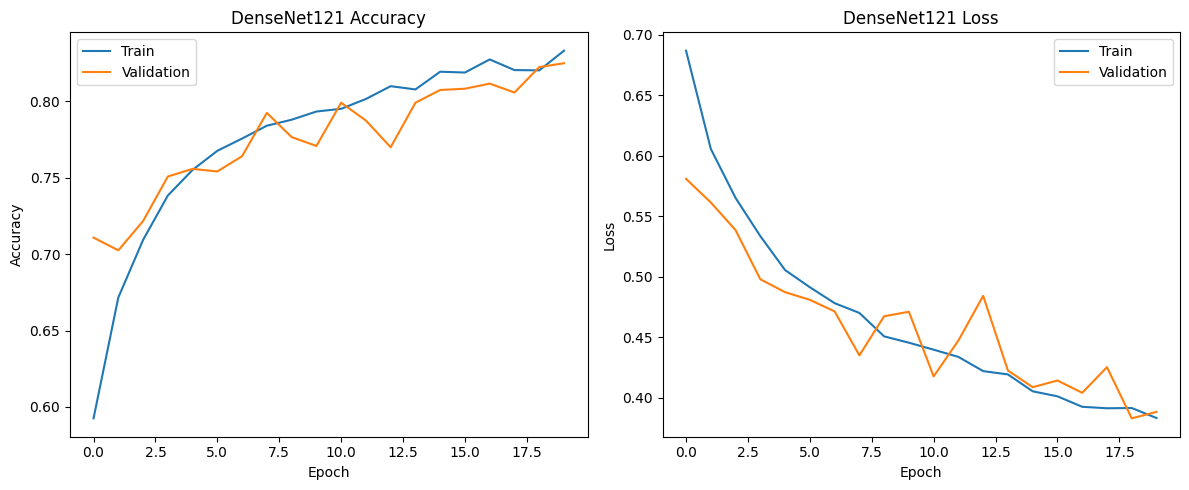

38/38 ━━━━━━━━━━━━━━━━━━━━ 112s 3s/step - accuracy: 0.8350 - loss: 0.3647

Test Loss: 0.3647
Test Accuracy: 0.835
38/38 ━━━━━━━━━━━━━━━━━━━━ 126s 3s/step


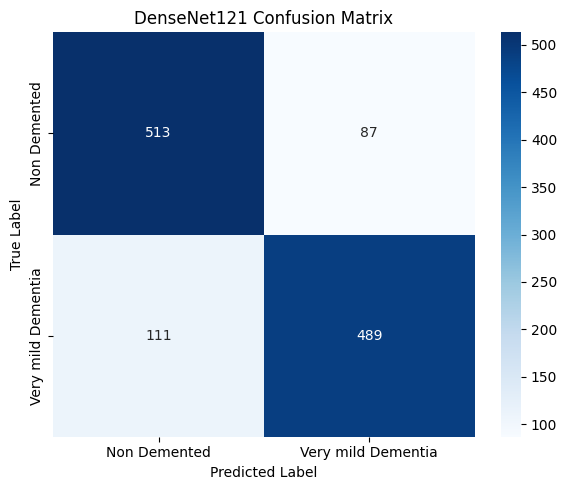


Classification Report:
                    precision    recall  f1-score   support

      Non Demented     0.8221    0.8550    0.8382       600
Very mild Dementia     0.8490    0.8150    0.8316       600

          accuracy                         0.8350      1200
         macro avg     0.8355    0.8350    0.8349      1200
      weighted avg     0.8355    0.8350    0.8349      1200



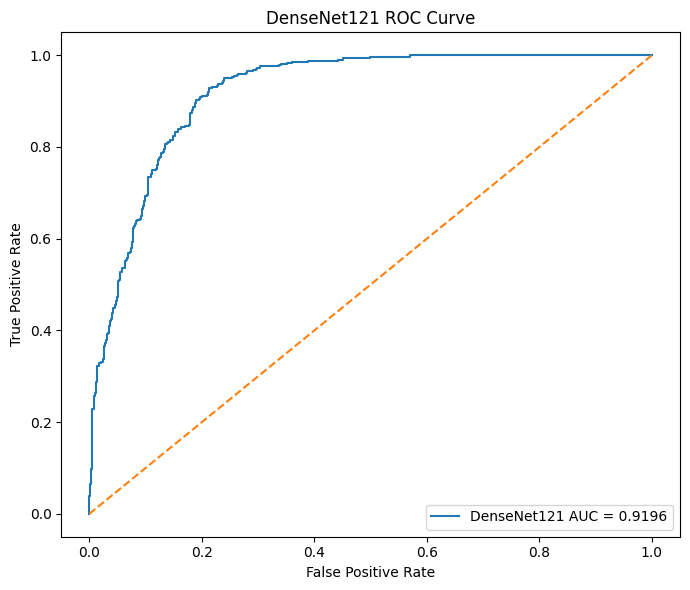

ROC-AUC: 0.9196


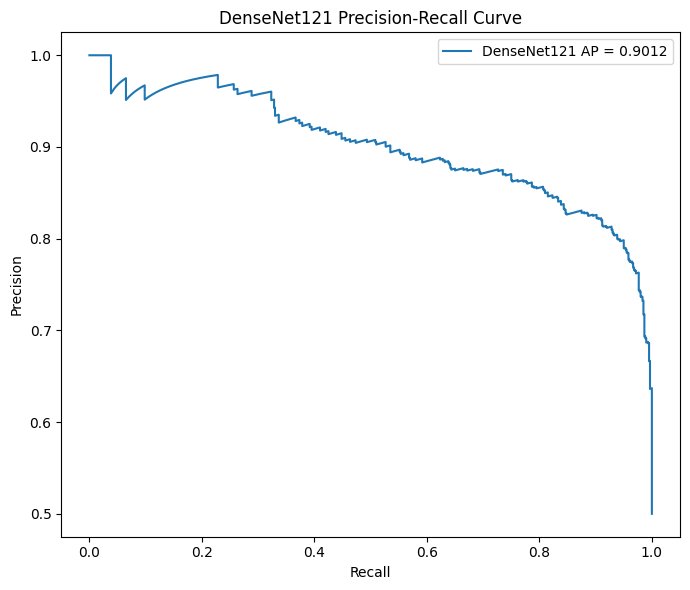

Average Precision: 0.9012

Performance Metrics:
True Negative (TN): 513
False Positive (FP): 87
False Negative (FN): 111
True Positive (TP): 489
Sensitivity: 0.815
Specificity: 0.855
38/38 ━━━━━━━━━━━━━━━━━━━━ 113s 3s/step

Inference Performance:
Total Inference Time: 113.194 sec
Time per Image: 0.094328 sec


FileNotFoundError: [WinError 2] The system cannot find the file specified: 'densenet121_model.h5'

In [6]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import time

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

# =========================
# ============================================================
# DATASET PATH
# ============================================================

base_path = r"D:\Downloads\balanced_data"

categories = [
    "Non Demented",
    "Very mild Dementia"
]

label_map = {
    "Non Demented": 0,
    "Very mild Dementia": 1
}
# =========================
# 2. LOAD DATA
# =========================
for category in categories:
    folder = os.path.join(base_path, category)

    for file in os.listdir(folder):
        image_paths.append(os.path.join(folder, file))
        labels.append(category)

df = pd.DataFrame({
    'image_path': image_paths,
    'label': labels
})

df['label'] = df['label'].map({
    'Non Demented': 0,
    'Very mild Dementia': 1
})

# =========================
# 3. SPLIT
# =========================
train_df, temp_df = train_test_split(
    df,
    test_size=0.3,
    stratify=df['label'],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df['label'],
    random_state=42
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

# =========================
# 4. AUGMENTATION
# =========================
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=15,
    zoom_range=0.15,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

# =========================
# 5. GENERATORS
# =========================
train_gen = train_datagen.flow_from_dataframe(
    train_df,
    x_col='image_path',
    y_col='label',
    target_size=(224, 224),
    batch_size=32,
    class_mode='raw'
)

val_gen = val_datagen.flow_from_dataframe(
    val_df,
    x_col='image_path',
    y_col='label',
    target_size=(224, 224),
    batch_size=32,
    class_mode='raw'
)

test_gen = val_datagen.flow_from_dataframe(
    test_df,
    x_col='image_path',
    y_col='label',
    target_size=(224, 224),
    batch_size=32,
    class_mode='raw',
    shuffle=False
)

# =========================
# 6. DENSENET121 MODEL
# =========================
base_model = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze most layers
for layer in base_model.layers[:-4]:
    layer.trainable = False

# Fine-tune last 4 layers
for layer in base_model.layers[-4:]:
    layer.trainable = True

model = Sequential([
    base_model,

    GlobalAveragePooling2D(),

    Dense(256, activation='relu'),
    Dropout(0.5),

    Dense(128, activation='relu'),
    Dropout(0.3),

    Dense(1, activation='sigmoid')
])

# =========================
# 7. COMPILE
# =========================
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Display model summary
model.summary()

# =========================
# 8. TRAIN (50 EPOCHS)
# =========================
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20
)

# =========================
# 9. SAVE MODEL (.h5)
# =========================
model.save("densenet121_model Alzheimer.h5")

print("Model saved as: densenet121_model Alzheimer.h5")

# =========================
# 10. TRAINING PLOTS
# =========================
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    history.history['accuracy'],
    label='Train'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation'
)

plt.legend()
plt.title("DenseNet121 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

# Loss
plt.subplot(1, 2, 2)

plt.plot(
    history.history['loss'],
    label='Train'
)

plt.plot(
    history.history['val_loss'],
    label='Validation'
)

plt.legend()
plt.title("DenseNet121 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.tight_layout()
plt.show()

# =========================
# 11. TEST
# =========================
test_loss, test_acc = model.evaluate(test_gen)

print("\nTest Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_acc, 4))

# =========================
# 12. PREDICTIONS
# =========================
y_true = test_df['label'].values

y_probs = model.predict(test_gen)

# Convert probabilities to 1D array
y_probs = y_probs.ravel()

# Classification threshold
y_pred = (y_probs > 0.5).astype(int)

# =========================
# 13. CONFUSION MATRIX
# =========================
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non Demented', 'Very mild Dementia'],
    yticklabels=['Non Demented', 'Very mild Dementia']
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("DenseNet121 Confusion Matrix")

plt.tight_layout()
plt.show()

# =========================
# CLASSIFICATION REPORT
# =========================
print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            'Non Demented',
            'Very mild Dementia'
        ],
        digits=4
    )
)

# =========================
# 14. ROC CURVE
# =========================
fpr, tpr, thresholds = roc_curve(
    y_true,
    y_probs
)

roc_auc = auc(
    fpr,
    tpr
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"DenseNet121 AUC = {roc_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    '--'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("DenseNet121 ROC Curve")
plt.legend()

plt.tight_layout()
plt.show()

print("ROC-AUC:", round(roc_auc, 4))

# =========================
# 15. PRECISION-RECALL CURVE
# =========================
precision, recall, thresholds_pr = precision_recall_curve(
    y_true,
    y_probs
)

ap_score = average_precision_score(
    y_true,
    y_probs
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall,
    precision,
    label=f"DenseNet121 AP = {ap_score:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("DenseNet121 Precision-Recall Curve")
plt.legend()

plt.tight_layout()
plt.show()

print("Average Precision:", round(ap_score, 4))

# =========================
# 16. SENSITIVITY & SPECIFICITY
# =========================
tn, fp, fn, tp = confusion_matrix(
    y_true,
    y_pred
).ravel()

sensitivity = tp / (tp + fn)

specificity = tn / (tn + fp)

print("\nPerformance Metrics:")
print("True Negative (TN):", tn)
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)
print("True Positive (TP):", tp)

print("Sensitivity:", round(sensitivity, 4))
print("Specificity:", round(specificity, 4))

# =========================
# 17. INFERENCE TIME
# =========================

# Reset test generator
test_gen.reset()

start = time.time()

_ = model.predict(
    test_gen,
    verbose=1
)

end = time.time()

total_time = end - start

avg_time = total_time / len(test_df)

print("\nInference Performance:")
print(
    "Total Inference Time:",
    round(total_time, 4),
    "sec"
)

print(
    "Time per Image:",
    round(avg_time, 6),
    "sec"
)

# =========================
# 18. MODEL SIZE
# =========================
model_file = "densenet121_model Alzheimer.h5"

size_mb = os.path.getsize(
    model_file
) / (1024 * 1024)

print("\nModel Information:")
print(
    "Model Size:",
    round(size_mb, 2),
    "MB"
)

# =========================
# 19. TRAINABLE PARAMETERS
# =========================
trainable_params = np.sum([
    np.prod(v.shape)
    for v in model.trainable_weights
])

non_trainable_params = np.sum([
    np.prod(v.shape)
    for v in model.non_trainable_weights
])

print(
    "Trainable Parameters:",
    trainable_params
)

print(
    "Non-trainable Parameters:",
    non_trainable_params
)

print(
    "Total Parameters:",
    trainable_params + non_trainable_params
)

In [7]:
# 18. MODEL SIZE
# =========================
model_file = "densenet121_model Alzheimer.h5"

size_mb = os.path.getsize(
    model_file
) / (1024 * 1024)

print("\nModel Information:")
print(
    "Model Size:",
    round(size_mb, 2),
    "MB"
)



Model Information:
Model Size: 31.36 MB


In [8]:
# 19. TRAINABLE PARAMETERS
# =========================
trainable_params = np.sum([
    np.prod(v.shape)
    for v in model.trainable_weights
])

non_trainable_params = np.sum([
    np.prod(v.shape)
    for v in model.non_trainable_weights
])

print(
    "Trainable Parameters:",
    trainable_params
)

print(
    "Non-trainable Parameters:",
    non_trainable_params
)

print(
    "Total Parameters:",
    trainable_params + non_trainable_params
)

Trainable Parameters: 334337
Non-trainable Parameters: 6998592
Total Parameters: 7332929
